# Notebook 2: Chunking Experiments

## Purpose
**Research Question 1 (RQ1): Impact of Chunking Strategy**

Compare fixed-size vs structure-aware chunking strategies:
- Analyze chunk count and token distribution
- Evaluate page metadata coverage
- Assess table/figure preservation
- Generate comparative visualizations

## Outputs
- Side-by-side comparison table
- Token distribution histogram
- Chunking artifacts cached for downstream use

In [1]:
import sys
from pathlib import Path

project_root = Path().resolve().parent
sys.path.insert(0, str(project_root))

import pandas as pd
import json
import matplotlib.pyplot as plt
from collections import defaultdict

from rag.config import ARTIFACTS_DIR, COMPANY_MAP, get_default_pipeline_config
from rag.parser import parse_all_reports
from rag.chunker import chunk_report, estimate_tokens

print(f"Project root: {project_root}")
print(f"Artifacts directory: {ARTIFACTS_DIR}")

Project root: /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot
Artifacts directory: /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/data/artifacts


In [2]:
# Control smoke test mode
SMOKE_TEST = True

# Get default config
config = get_default_pipeline_config()
print(f"Chunking strategy: {config['chunking_strategy']}")
print(f"Chunk size (tokens): {config['chunk_size_tokens']}")
print(f"Overlap (tokens): {config['chunk_overlap_tokens']}")

if SMOKE_TEST:
    print("\nSMOKE TEST MODE: Processing 2 companies only")

Chunking strategy: structure_aware
Chunk size (tokens): 512
Overlap (tokens): 64

SMOKE TEST MODE: Processing 2 companies only


In [3]:
# Parse reports
print("Parsing reports...")
all_parsed = parse_all_reports()

if SMOKE_TEST:
    companies_to_process = list(all_parsed.keys())[:2]
    reports = {k: all_parsed[k] for k in companies_to_process}
else:
    reports = all_parsed

print(f"Processing {len(reports)} reports")

Parsing reports...
  Parsing AkerBP_2024.md...
    -> 1019 elements, 136 pages
  Parsing BASF_2024.md...
    -> 1200 elements, 327 pages
  Parsing Eni_2024.md...
    -> 957 elements, 267 pages
  Parsing Equinor_2024.md...
    -> 1889 elements, 184 pages
  Parsing Galp_2024.md...
    -> 573 elements, 99 pages
  Parsing Helleniq_2024.md...
    -> 1621 elements, 291 pages
  Parsing Mol_2024.md...
    -> 1594 elements, 293 pages
  Parsing Motoroil_2024.md...
    -> 1627 elements, 282 pages
  Parsing Neste_2024.md...
    -> 738 elements, 154 pages
  Parsing OMV_2024.md...
    -> 2520 elements, 422 pages
  Parsing Petrom_2024.md...
    -> 2693 elements, 238 pages
  Parsing Repsol_2024.md...
    -> 2958 elements, 255 pages
  Parsing SBMOffshore_2024.md...
    -> 2399 elements, 162 pages
  Parsing Shell_2024.md...
    -> 2457 elements, 475 pages
  Parsing Solvay_2024.md...
    -> 1250 elements, 187 pages
  Parsing TotalEnergies_2024.md...
    -> 2816 elements, 420 pages
  Parsing Vopak_2024.md

## Fixed-Size Chunking

In [4]:
# Run fixed-size chunking
fixed_config = {**config, 'chunking_strategy': 'fixed_size'}
fixed_chunks = []

for company, parsed_report in reports.items():
    chunks = chunk_report(
        parsed_report,
        strategy='fixed_size',
        chunk_size_tokens=fixed_config['chunk_size_tokens'],
        chunk_overlap_tokens=fixed_config['chunk_overlap_tokens']
    )
    fixed_chunks.extend(chunks)

# Compute stats
fixed_stats = {
    'Strategy': 'Fixed-Size',
    'Chunk Count': len(fixed_chunks),
    'Avg Token Count': round(sum(c.token_count for c in fixed_chunks) / len(fixed_chunks), 1) if fixed_chunks else 0,
    'Min Tokens': min((c.token_count for c in fixed_chunks), default=0),
    'Max Tokens': max((c.token_count for c in fixed_chunks), default=0),
}

print(f"Fixed-Size Chunking Results:")
for key, val in fixed_stats.items():
    print(f"  {key}: {val}")

Fixed-Size Chunking Results:
  Strategy: Fixed-Size
  Chunk Count: 415
  Avg Token Count: 509.4
  Min Tokens: 343
  Max Tokens: 510


## Structure-Aware Chunking

In [5]:
# Run structure-aware chunking
struct_config = {**config, 'chunking_strategy': 'structure_aware'}
struct_chunks = []

for company, parsed_report in reports.items():
    chunks = chunk_report(
        parsed_report,
        strategy='structure_aware',
        chunk_size_tokens=struct_config['chunk_size_tokens'],
        chunk_overlap_tokens=struct_config['chunk_overlap_tokens']
    )
    struct_chunks.extend(chunks)

# Compute stats
struct_stats = {
    'Strategy': 'Structure-Aware',
    'Chunk Count': len(struct_chunks),
    'Avg Token Count': round(sum(c.token_count for c in struct_chunks) / len(struct_chunks), 1) if struct_chunks else 0,
    'Min Tokens': min((c.token_count for c in struct_chunks), default=0),
    'Max Tokens': max((c.token_count for c in struct_chunks), default=0),
}

print(f"Structure-Aware Chunking Results:")
for key, val in struct_stats.items():
    print(f"  {key}: {val}")

Structure-Aware Chunking Results:
  Strategy: Structure-Aware
  Chunk Count: 658
  Avg Token Count: 311.1
  Min Tokens: 2
  Max Tokens: 535


## Comparison Summary

In [6]:
# Create comparison table
comparison_data = []

# Fixed-size metrics
fixed_with_page = sum(1 for c in fixed_chunks if c.page_number >= 0)
fixed_with_tables = sum(1 for c in fixed_chunks if c.contains_table)
comparison_data.append({
    'Strategy': 'Fixed-Size',
    'Chunk Count': fixed_stats['Chunk Count'],
    'Avg Tokens': fixed_stats['Avg Token Count'],
    'With Page Info': fixed_with_page,
    'Page Coverage %': round(fixed_with_page / len(fixed_chunks) * 100, 1) if fixed_chunks else 0,
    'With Tables': fixed_with_tables,
    'Table %': round(fixed_with_tables / len(fixed_chunks) * 100, 1) if fixed_chunks else 0,
})

# Structure-aware metrics
struct_with_page = sum(1 for c in struct_chunks if c.page_number >= 0)
struct_with_tables = sum(1 for c in struct_chunks if c.contains_table)
comparison_data.append({
    'Strategy': 'Structure-Aware',
    'Chunk Count': struct_stats['Chunk Count'],
    'Avg Tokens': struct_stats['Avg Token Count'],
    'With Page Info': struct_with_page,
    'Page Coverage %': round(struct_with_page / len(struct_chunks) * 100, 1) if struct_chunks else 0,
    'With Tables': struct_with_tables,
    'Table %': round(struct_with_tables / len(struct_chunks) * 100, 1) if struct_chunks else 0,
})

comparison_df = pd.DataFrame(comparison_data)
print("\nStrategy Comparison:")
print(comparison_df.to_string(index=False))


Strategy Comparison:
       Strategy  Chunk Count  Avg Tokens  With Page Info  Page Coverage %  With Tables  Table %
     Fixed-Size          415       509.4             415            100.0          155     37.3
Structure-Aware          658       311.1             658            100.0          160     24.3


## Token Distribution Analysis

Token distribution plot saved to: data/artifacts/chunking_token_distribution.png


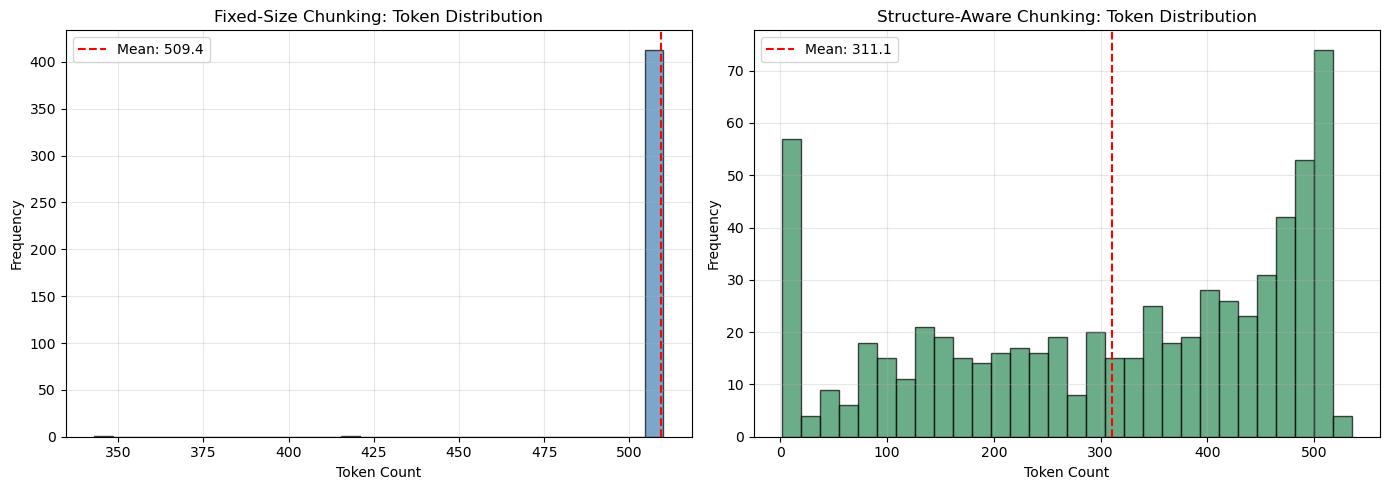

In [7]:
# Create histogram of token counts per strategy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Fixed-size histogram
fixed_tokens = [c.token_count for c in fixed_chunks]
ax1.hist(fixed_tokens, bins=30, color='steelblue', edgecolor='black', alpha=0.7)
ax1.set_xlabel('Token Count')
ax1.set_ylabel('Frequency')
ax1.set_title('Fixed-Size Chunking: Token Distribution')
ax1.axvline(fixed_stats['Avg Token Count'], color='red', linestyle='--', label=f"Mean: {fixed_stats['Avg Token Count']}")
ax1.legend()
ax1.grid(alpha=0.3)

# Structure-aware histogram
struct_tokens = [c.token_count for c in struct_chunks]
ax2.hist(struct_tokens, bins=30, color='seagreen', edgecolor='black', alpha=0.7)
ax2.set_xlabel('Token Count')
ax2.set_ylabel('Frequency')
ax2.set_title('Structure-Aware Chunking: Token Distribution')
ax2.axvline(struct_stats['Avg Token Count'], color='red', linestyle='--', label=f"Mean: {struct_stats['Avg Token Count']}")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / 'chunking_token_distribution.png', dpi=100, bbox_inches='tight')
print("Token distribution plot saved to: data/artifacts/chunking_token_distribution.png")
plt.show()

## Page Metadata Quality

In [8]:
# Compare page coverage ratios
page_quality = []

# Fixed-size analysis
fixed_with_spans = sum(1 for c in fixed_chunks if len(c.page_span) > 0)
page_quality.append({
    'Strategy': 'Fixed-Size',
    'Chunks with Page Info': fixed_with_page,
    'Chunks with Page Spans': fixed_with_spans,
    'Avg Pages per Chunk': round(sum(len(c.page_span) for c in fixed_chunks) / len(fixed_chunks), 2) if fixed_chunks else 0,
})

# Structure-aware analysis
struct_with_spans = sum(1 for c in struct_chunks if len(c.page_span) > 0)
page_quality.append({
    'Strategy': 'Structure-Aware',
    'Chunks with Page Info': struct_with_page,
    'Chunks with Page Spans': struct_with_spans,
    'Avg Pages per Chunk': round(sum(len(c.page_span) for c in struct_chunks) / len(struct_chunks), 2) if struct_chunks else 0,
})

page_df = pd.DataFrame(page_quality)
print("\nPage Metadata Quality:")
print(page_df.to_string(index=False))


Page Metadata Quality:
       Strategy  Chunks with Page Info  Chunks with Page Spans  Avg Pages per Chunk
     Fixed-Size                    415                     415                 1.87
Structure-Aware                    658                     658                 1.34


## Save Chunking Artifacts

In [9]:
# Save chunks as JSON for downstream use
def chunks_to_dicts(chunks):
    return [c.to_dict() for c in chunks]

fixed_path = ARTIFACTS_DIR / "chunks_fixed_size.json"
struct_path = ARTIFACTS_DIR / "chunks_structure_aware.json"

with open(fixed_path, 'w', encoding='utf-8') as f:
    json.dump(chunks_to_dicts(fixed_chunks), f, indent=2)

with open(struct_path, 'w', encoding='utf-8') as f:
    json.dump(chunks_to_dicts(struct_chunks), f, indent=2)

print(f"Fixed-size chunks saved to: {fixed_path}")
print(f"Structure-aware chunks saved to: {struct_path}")
print(f"\nChunking experiment complete. {len(fixed_chunks)} + {len(struct_chunks)} chunks cached.")

Fixed-size chunks saved to: /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/data/artifacts/chunks_fixed_size.json
Structure-aware chunks saved to: /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/data/artifacts/chunks_structure_aware.json

Chunking experiment complete. 415 + 658 chunks cached.
